In [ ]:
import pandas as pd
import numpy as np
import phik
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path



data = {}
for f in sorted(Path("../dataset/cleaned/").glob("*.csv")):
    data[f.stem] = pd.read_csv(f)

df = data["Iisingintie1_clean"]

In [ ]:
df

        Timer(ms)    Loc(m)  CElev(m)  Roll(deg)  Pitch(deg)  Yaw(deg)  \
0      45900476.5  3760.479   109.111     2.0162     -1.8280    5.3424   
1      45900479.0  3760.479   109.112     2.0173     -1.8276    5.3428   
2      45900474.0  3760.479   109.111     2.0165     -1.8282    5.3417   
3      45900481.5  3760.479   109.112     2.0172     -1.8274    5.3428   
4      45900471.5  3760.479   109.111     2.0165     -1.8283    5.3408   
...           ...       ...       ...        ...         ...       ...   
83592  46105337.4  6910.462   119.601     2.5315     -3.0370  158.5733   
83593  46105339.9  6910.481   119.601     2.5313     -3.0349  158.5734   
83594  46105342.4  6910.500   119.601     2.5311     -3.0331  158.5734   
83595  46105344.9  6910.520   119.601     2.5305     -3.0328  158.5729   
83596  46105347.4  6910.539   119.600     2.5297     -3.0346  158.5723   

          AccX     AccY      AccZ     GyrX     GyrY     GyrZ  Speed_kmh  \
0      0.30559  0.35245   9.83279 -0

### Section 1: cut one drive into windows

* The windows have to be cut by meters, not rows: the same 5 m of road can be 90 rows or 171 rows, depending on speed.

In [ ]:
# Give every row a window number 

WINDOW_M = 5

df["window"] = (df["Loc(m)"] // WINDOW_M).astype(int)

print("Number of windows:", d["window"].nunique())
print(d.groupby("window").size().describe())

Number of windows: 631
count     631.000000
mean      132.483360
std       173.613892
min        28.000000
25%       117.000000
50%       121.000000
75%       123.000000
max      4376.000000
dtype: float64


### Section 2: label each window

In [ ]:
# mark the frost-heave rows

df["is_heave"] = d[f"Frostbumps"]

In [ ]:
# summarize each window in one row

windows = df.groupby("window").agg(
    start_m=("Loc(m)", "min"),
    end_m=("Loc(m)", "max"),
    heave_frac=("is_heave", "mean"),
)
windows["length_m"] = windows["end_m"] - windows["start_m"]

print(windows.head(10))

         start_m     end_m  heave_frac  length_m
window                                          
752     3760.479  3764.998         0.0     4.519
753     3765.002  3769.996         0.0     4.994
754     3770.005  3774.995         0.0     4.990
755     3775.008  3779.995         0.0     4.987
756     3780.012  3784.992         0.0     4.980
757     3785.014  3789.999         0.0     4.985
758     3790.025  3794.978         0.0     4.953
759     3795.007  3799.987         0.0     4.980
760     3800.018  3804.977         0.0     4.959
761     3805.009  3809.970         0.0     4.961


In [22]:
windows = windows[windows["length_m"] >= 4.5]      # remove the short last window(s)

def label_window(frac):
    if frac > 0.5:
        return "bump"
    elif frac == 0:
        return "no bump"
    else:
        return "left out"

windows["label"] = windows["heave_frac"].apply(label_window)
print(windows["label"].value_counts())

label
no bump     504
bump        113
left out     13
Name: count, dtype: int64


* “frost heaves in this data are on average about 50 m long.”

In [23]:
def size_group(v):
    if v in (1, 2):
        return "small"
    elif v == 3:
        return "medium"
    elif v == 5:
        return "large"
    return None

heave_rows = d["is_heave"]
# get the most common values for each window
windows["vaikeus"] = heave_rows.groupby("window")["vaikeus"].agg(lambda s: s.mode()[0])
windows["posneg"] = heave_rows.groupby("window")["posneg"].agg(lambda s: s.mode()[0])
# assign size groups
windows["size_group"] = windows["vaikeus"].apply(size_group)

# size and up/down only make sense for bump windows
windows.loc[windows["label"] != "bump", ["vaikeus", "posneg", "size_group"]] = None

print(windows.loc[windows["label"] == "bump", "size_group"].value_counts())

KeyError: 'window'

* “larger frost heaves tend to be longer.”

### Section 3: compute the features

In [ ]:
SENSORS = ["AccX", "AccY", "AccZ", "GyrX", "GyrY", "GyrZ", "Roll(deg)", "Pitch(deg)"]

def window_features(g):
    feats = {"speed": g["Speed_kmh"].mean()}
    for col in SENSORS:
        x = g[col]
        name = col.split("(")[0]                  # "Pitch(deg)" → "Pitch"
        feats[f"{name}_std"] = x.std()
        feats[f"{name}_range"] = x.max() - x.min()
        feats[f"{name}_mean"] = x.mean()
    return pd.Series(feats)

features = df.groupby("window")[SENSORS + ["Speed (m/s)"]].apply(window_features)
windows = windows.join(features)

print(windows.shape)
windows.head()

KeyError: "Columns not found: 'Speed (m/s)'"

In [ ]:
# Let's check if the features actually behave like we expect.
check_cols = ["GyrY_std", "Pitch_std", "AccZ_std", "speed"]
print(windows.groupby("label")[check_cols].mean().round(4))

          GyrY_std  Pitch_std  AccZ_std    speed
label                                           
bump        0.0705     0.3150    1.8086  20.3373
left out    0.0452     0.1531    0.8463  20.0329
no bump     0.0253     0.0939    0.9425  21.7866


In [ ]:
from data_utils import make_windows

parts = []
for name, df2 in data.items():
    parts.append(make_windows(df2, name))

all_windows = pd.concat(parts, ignore_index=True)

print(all_windows.shape)
print(pd.crosstab(all_windows["road"], all_windows["label"]))

(2770, 45)
label             bump  left out  no bump
road                                     
Iisingintie        348        28     1465
Kaittiaisentie      30         6      584
sinetänsalmentie   140         8      161


In [ ]:
Path("data_features").mkdir(exist_ok=True)
all_windows.to_csv("data_features/windows_5m.csv", index=False)

### which features are related to bumps?

In [ ]:
feature_cols = [c for c in all_windows.columns if c.endswith(("_std", "_range", "_mean"))] + ["speed"]

sub = all_windows[all_windows["label"] != "left out"].copy()
sub["is_bump"] = (sub["label"] == "bump").astype(int)

print(len(feature_cols), "features,", len(sub), "windows")

30 features, 2728 windows


In [ ]:
pearson = sub[feature_cols].corrwith(sub["is_bump"])

phik_m = sub[feature_cols + ["is_bump"]].phik_matrix(interval_cols=feature_cols)
phik_target = phik_m["is_bump"].drop("is_bump")

relevance = pd.DataFrame({"pearson": pearson, "phik": phik_target}).round(2)
relevance = relevance.sort_values("phik", ascending=False)
print(relevance)

                 pearson  phik
GyrY_range          0.47  0.48
AccZ_mean          -0.01  0.47
GyrY_std            0.46  0.47
AccZ_range          0.33  0.43
GyrY_mean           0.02  0.39
GyrX_std            0.37  0.37
AccZ_std            0.37  0.36
GyrX_mean          -0.07  0.35
GyrX_range          0.34  0.35
AccX_mean          -0.12  0.33
speed               0.08  0.31
GyrZ_std            0.29  0.29
GyrZ_range          0.27  0.28
AccY_std            0.18  0.24
Pitch_std           0.30  0.23
Pitch_range         0.33  0.22
AccY_range          0.16  0.22
AccY_mean           0.01  0.22
AccX_std            0.14  0.14
AccX_range          0.13  0.12
Roll_mean           0.01  0.11
Pitch_mean          0.06  0.11
GyrZ_mean          -0.01  0.09
Roll_std            0.10  0.03
Roll_range          0.09  0.00
RBCSV60_mean        0.10  0.00
RBCSV60_std         0.08  0.00
RBCSV80_mean        0.09  0.00
RBCSV80_std         0.08  0.00
RBCSV_delta_std     0.07  0.00


#### Does each feature work within every road?

In [ ]:
# correlation within each road
rows = {}
for road, g in sub.groupby("road"):
    rows[road] = g[feature_cols].corrwith(g["is_bump"])

per_road = pd.DataFrame(rows).round(2)
per_road["all roads"] = relevance["pearson"]
print(per_road.sort_values("all roads", ascending=False))

                 Iisingintie  Kaittiaisentie  sinetänsalmentie  all roads
GyrY_range              0.53            0.62              0.39       0.47
GyrY_std                0.53            0.61              0.37       0.46
GyrX_std                0.42            0.33              0.27       0.37
AccZ_std                0.36            0.53              0.42       0.37
GyrX_range              0.41            0.30              0.25       0.34
AccZ_range              0.33            0.45              0.43       0.33
Pitch_range             0.55            0.58             -0.00       0.33
Pitch_std               0.53            0.55              0.01       0.30
GyrZ_std                0.35            0.24              0.12       0.29
GyrZ_range              0.35            0.23              0.11       0.27
AccY_std                0.22            0.14              0.18       0.18
AccY_range              0.21            0.14              0.19       0.16
AccX_std                0.16          

In [ ]:
# Do the drives have different averages?
print(all_windows.groupby("drive")[["AccZ_mean", "GyrY_mean", "speed"]].mean().round(3))

                                                   AccZ_mean  GyrY_mean  \
drive                                                                     
Iisingintie_Acc1_m800_RDMC_2026-05-06_123750           9.819      0.001   
Iisingintie_Acc1_m801_RDMC_2026-05-06_124454           9.817      0.001   
Iisingintie_Acc1_m802_RDMC_2026-05-06_125211           9.815      0.001   
Kaittiaisentie_Acc1_RDMC_2026-05-06_132147             9.821      0.000   
sinetänsalmentie_Acc1_m792_RDMC_2026-05-06_112539      9.893     -0.001   
sinetänsalmentie_Acc1_m793_RDMC_2026-05-06_112757      9.911     -0.001   
sinetänsalmentie_Acc1_m794_RDMC_2026-05-06_112959      9.885     -0.001   
sinetänsalmentie_Acc1_m795_RDMC_2026-05-06_113156      9.834      0.001   

                                                    speed  
drive                                                      
Iisingintie_Acc1_m800_RDMC_2026-05-06_123750       21.481  
Iisingintie_Acc1_m801_RDMC_2026-05-06_124454       16.479  
Iisingint

### Feature selection (step 4a + 4c)

- Dropped: all `_mean` features (8). Strong overall phik but ~0 correlation within every road → they identify the road/drive (e.g. AccZ_mean is higher on Sinetänsalmentie, which also has 46% bump windows), not the bump.
- Dropped: Roll_std, Roll_range. Inconsistent across roads (negative on Sinetänsalmentie).
- Kept (consistent in all roads): GyrY, AccZ, GyrX, GyrZ, AccY, AccX (std and range).
- Kept with caution: Pitch_std, Pitch_range. Strong on Iisingintie and Kaittiaisentie, ~0 on Sinetänsalmentie.
- Kept for physical reasons: speed. Low correlation alone, but bump strength depends on speed.
- Best single features: GyrY_std / GyrY_range (0.38–0.62 within every road).

#### Are some kept features duplicates?

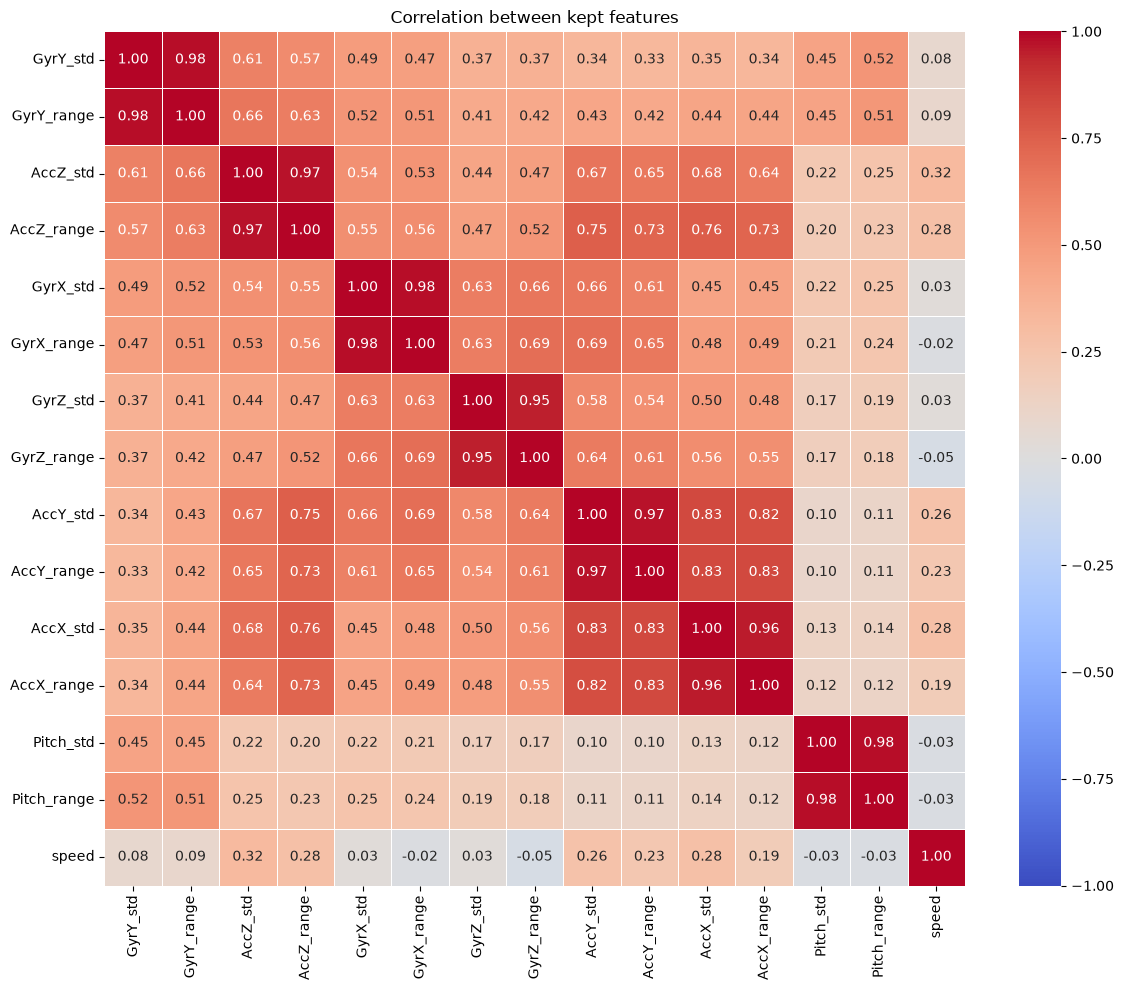

[0.98 0.97 0.98 0.95 0.97 0.96 0.98]


In [ ]:
kept = [
    f"{s}_{stat}"
    for s in ["GyrY", "AccZ", "GyrX", "GyrZ", "AccY", "AccX", "Pitch"]
    for stat in ["std", "range"]
] + ["speed"]

corr = sub[kept].corr().round(2)

plt.figure(figsize=(12, 10))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Correlation between kept features")
plt.tight_layout()
plt.savefig("figures/feature_correlation.png", dpi=150)
plt.show()

print(
    corr.loc[
        [f"{s}_std" for s in ["GyrY", "AccZ", "GyrX", "GyrZ", "AccY", "AccX", "Pitch"]],
        [f"{s}_range" for s in ["GyrY", "AccZ", "GyrX", "GyrZ", "AccY", "AccX", "Pitch"]]
    ].values.diagonal()
)

### Feature selection (step 4b: multicollinearity)

- Each sensor's `_std` and `_range` are near-duplicates (correlation 0.95–0.98) → kept only `_std` (uses all values in the window, more robust to single spikes than max − min).
- AccX/AccY (0.83) and AccZ/AccX/AccY (0.65–0.76) are related but below the 0.9 rule of thumb → all kept.
- Speed is nearly independent of all other features → adds unique information.

**Final features (8):** GyrY_std, AccZ_std, GyrX_std, GyrZ_std, AccY_std, AccX_std, Pitch_std, speed

## Conclusions

**Windowing**
- Each drive is cut into fixed 5 m windows by distance: `window = Loc(m) // 5`. The same window number is the same piece of road in every drive of that road.
- Incomplete windows (< 4.5 m, at the end of a drive) are dropped.
- Labels: frost heave = `muu` 1 or 2. More than 50% of the window frost heave → bump; 0% → no bump; otherwise → left out (unreliable label edges).
- Bump windows also get size group (small 1–2 / medium 3 / large 5) and `posneg`.

**Window dataset** (saved as `data_features/windows_5m.csv`)
- 2,771 windows from 8 drives: 518 bump, 2,203 no bump, 50 left out.
- Share of bump windows differs strongly by road: Iisingintie 19%, Kaittiaisentie 5%, Sinetänsalmentie 46%.
- Frost heaves are long (~50 m on average on Iisingintie). Larger heaves are longer, so at window level "large" is over-represented (e.g. 70 large vs. 23 medium vs. 23 small windows in the 80 km/h drive), although at bump level the size groups are balanced (7 / 6 / 6).

**Feature selection: 25 candidates → 8**
- Candidates: std, range and mean of 8 sensors + speed.
- Dropped all `_mean` features: high phik overall but ~0 correlation within every road. They identify the road (e.g. AccZ_mean is higher on Sinetänsalmentie, which also has the most bumps), not the bump.
- Dropped Roll: inconsistent across roads.
- `_std` and `_range` of the same sensor are near-duplicates (0.95–0.98) → kept `_std` (more robust to single spikes).
- Speed kept for physical reasons: bump strength depends on speed, even though speed alone barely correlates with bumps.
- **Final features:** GyrY_std, AccZ_std, GyrX_std, GyrZ_std, AccY_std, AccX_std, Pitch_std, speed.
- Best single feature: GyrY_std (correlation 0.38–0.61 within every road).

**Notes for modelling (05)**
- Windows of the same bump are near-copies → test with one road held out, never split windows of one bump between training and test.
- Iisingintie provides ~2/3 of all windows and will dominate training.
- Pitch_std works on Iisingintie and Kaittiaisentie but not on Sinetänsalmentie. Watch performance on that road.
- Class imbalance (bump vs. no bump, size groups, up/down) → use class weights.

## RBCSV features (workshop point 1)

The workshop suggested the RBCSV columns as key features. First, check the column names.

In [ ]:
import pandas as pd
from pathlib import Path

# list the columns that contain "RBCSV" in the first cleaned data file
first_file = sorted(Path("data_clean").glob("*.csv"))[0]
df = pd.read_csv(first_file)
print([c for c in df.columns if "RBCSV" in c])

['RBCSV_80(cf)', 'RBCSV_60(cf)']


In [ ]:
# compute the median RBCSV values for each road and label
known = all_windows[all_windows["label"] != "left out"]
print(known.groupby(["road", "label"])[["RBCSV60_mean", "RBCSV80_mean", "RBCSV_delta"]].median().round(2))

                          RBCSV60_mean  RBCSV80_mean  RBCSV_delta
road             label                                           
Iisingintie      bump             0.57          0.66         0.08
                 no bump          0.23          0.28         0.04
Kaittiaisentie   bump             0.63          0.77         0.13
                 no bump          0.30          0.38         0.08
sinetänsalmentie bump             0.52          0.57         0.10
                 no bump          0.32          0.42         0.09


### One more check before the model: speed

* Why: remember how the raw std features gave lots of false alarms at 80 km/h, because faster driving means more shaking everywhere? We need to know whether RBCSV has the same problem. Iisingintie is perfect for testing this, because it has the same road driven at 3 speeds.

In [ ]:
print(known.groupby(["drive", "label"])[["RBCSV60_mean", "RBCSV80_mean", "speed"]].median().round(2))

                                                           RBCSV60_mean  \
drive                                             label                   
Iisingintie_Acc1_m800_RDMC_2026-05-06_123750      bump             0.56   
                                                  no bump          0.23   
Iisingintie_Acc1_m801_RDMC_2026-05-06_124454      bump             0.59   
                                                  no bump          0.23   
Iisingintie_Acc1_m802_RDMC_2026-05-06_125211      bump             0.54   
                                                  no bump          0.23   
Kaittiaisentie_Acc1_RDMC_2026-05-06_132147        bump             0.63   
                                                  no bump          0.30   
sinetänsalmentie_Acc1_m792_RDMC_2026-05-06_112539 bump             1.03   
                                                  no bump          0.37   
sinetänsalmentie_Acc1_m793_RDMC_2026-05-06_112757 bump             0.57   
                         

## Question to ask

“RBCSV is very stable between the Iisingintie drives, but on sinetänsalmentie the values at the bumps drop from drive to drive (m792 → m795). Is there a reason, e.g. how RBCSV is calculated?”

### Conclusion for now

RBCSV looks useful, but it isn’t 100% reliable. The fair way to decide is to test it in the model with our road split.